In [13]:
import heapq
import time
import sys
from collections import deque, defaultdict
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

print("All libraries imported successfully!")

All libraries imported successfully!


In [14]:
class RomeCityGraph:
    def __init__(self):
        self.graph = defaultdict(list)
        self.weights = {}
        self.nodes = [
            "colosseum", "roman_forum", "palatine_hill", "capitoline_hill",
            "pantheon", "trevi_fountain", "spanish_steps", "vatican_city",
            "st_peters_basilica", "sistine_chapel", "vatican_museums",
            "castel_sant_angelo", "piazza_navona", "campo_de_fiori",
            "trastevere", "villa_borghese", "borghese_gallery", "piazza_del_popolo",
            "via_del_corso", "piazza_venezia", "circus_maximus", "baths_of_caracalla",
            "appian_way", "catacombs", "testaccio", "san_giovanni"
        ]
        
        # Highway-like connections (not fully connected)
        connections = [
            ("colosseum", "roman_forum", 0.5),
            ("roman_forum", "palatine_hill", 0.2),
            ("palatine_hill", "circus_maximus", 0.5),
            ("roman_forum", "capitoline_hill", 0.4),
            ("capitoline_hill", "piazza_venezia", 0.3),
            ("piazza_venezia", "via_del_corso", 0.3),
            ("via_del_corso", "pantheon", 0.5),
            ("pantheon", "trevi_fountain", 0.8),
            ("trevi_fountain", "spanish_steps", 0.6),
            ("spanish_steps", "piazza_del_popolo", 0.7),
            ("piazza_del_popolo", "villa_borghese", 0.5),
            ("villa_borghese", "borghese_gallery", 0.2),
            ("pantheon", "piazza_navona", 0.4),
            ("piazza_navona", "campo_de_fiori", 0.4),
            ("campo_de_fiori", "trastevere", 0.8),
            ("trastevere", "vatican_city", 1.5),
            ("vatican_city", "st_peters_basilica", 0.1),
            ("vatican_city", "vatican_museums", 0.3),
            ("vatican_museums", "sistine_chapel", 0.1),
            ("st_peters_basilica", "castel_sant_angelo", 0.5),
            ("castel_sant_angelo", "piazza_navona", 1.0),
            ("trastevere", "testaccio", 1.2),
            ("testaccio", "baths_of_caracalla", 0.9),
            ("baths_of_caracalla", "circus_maximus", 0.6),
            ("circus_maximus", "colosseum", 0.8),
            ("baths_of_caracalla", "appian_way", 1.5),
            ("appian_way", "catacombs", 2.0),
            ("catacombs", "san_giovanni", 1.8),
            ("san_giovanni", "colosseum", 1.0),
            ("via_del_corso", "spanish_steps", 0.4),
            ("campo_de_fiori", "piazza_venezia", 0.7)
        ]
        
        for node1, node2, weight in connections:
            self.graph[node1].append(node2)
            self.graph[node2].append(node1)
            self.weights[(node1, node2)] = weight
            self.weights[(node2, node1)] = weight
    
    def get_neighbors(self, node):
        return self.graph[node]
    
    def get_weight(self, node1, node2):
        return self.weights.get((node1, node2), float('inf'))
    
    def visualize_graph(self):
        G = nx.Graph()
        
        for node in self.nodes:
            G.add_node(node)
        
        for (node1, node2), weight in self.weights.items():
            if not G.has_edge(node1, node2):
                G.add_edge(node1, node2, weight=weight)
        
        plt.figure(figsize=(14, 10))
        pos = nx.spring_layout(G, k=2, iterations=100, seed=42)
        
        nx.draw_networkx_nodes(G, pos, node_color='lightblue', 
                              node_size=1000, alpha=0.9)
        nx.draw_networkx_labels(G, pos, font_size=7, font_weight='bold')
        nx.draw_networkx_edges(G, pos, alpha=0.7, width=2)
        
        edge_labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels, font_size=6)
        
        plt.title("Rome City Graph - Landmarks and Connections", fontsize=14)
        plt.axis('off')
        plt.tight_layout()
        plt.show()

print("RomeCityGraph class defined successfully!")

RomeCityGraph class defined successfully!


Rome City Graph Search Algorithms
Graph created with 26 landmarks
Available landmarks: colosseum, roman_forum, palatine_hill, capitoline_hill, pantheon, trevi_fountain, spanish_steps, vatican_city, st_peters_basilica, sistine_chapel, vatican_museums, castel_sant_angelo, piazza_navona, campo_de_fiori, trastevere, villa_borghese, borghese_gallery, piazza_del_popolo, via_del_corso, piazza_venezia, circus_maximus, baths_of_caracalla, appian_way, catacombs, testaccio, san_giovanni


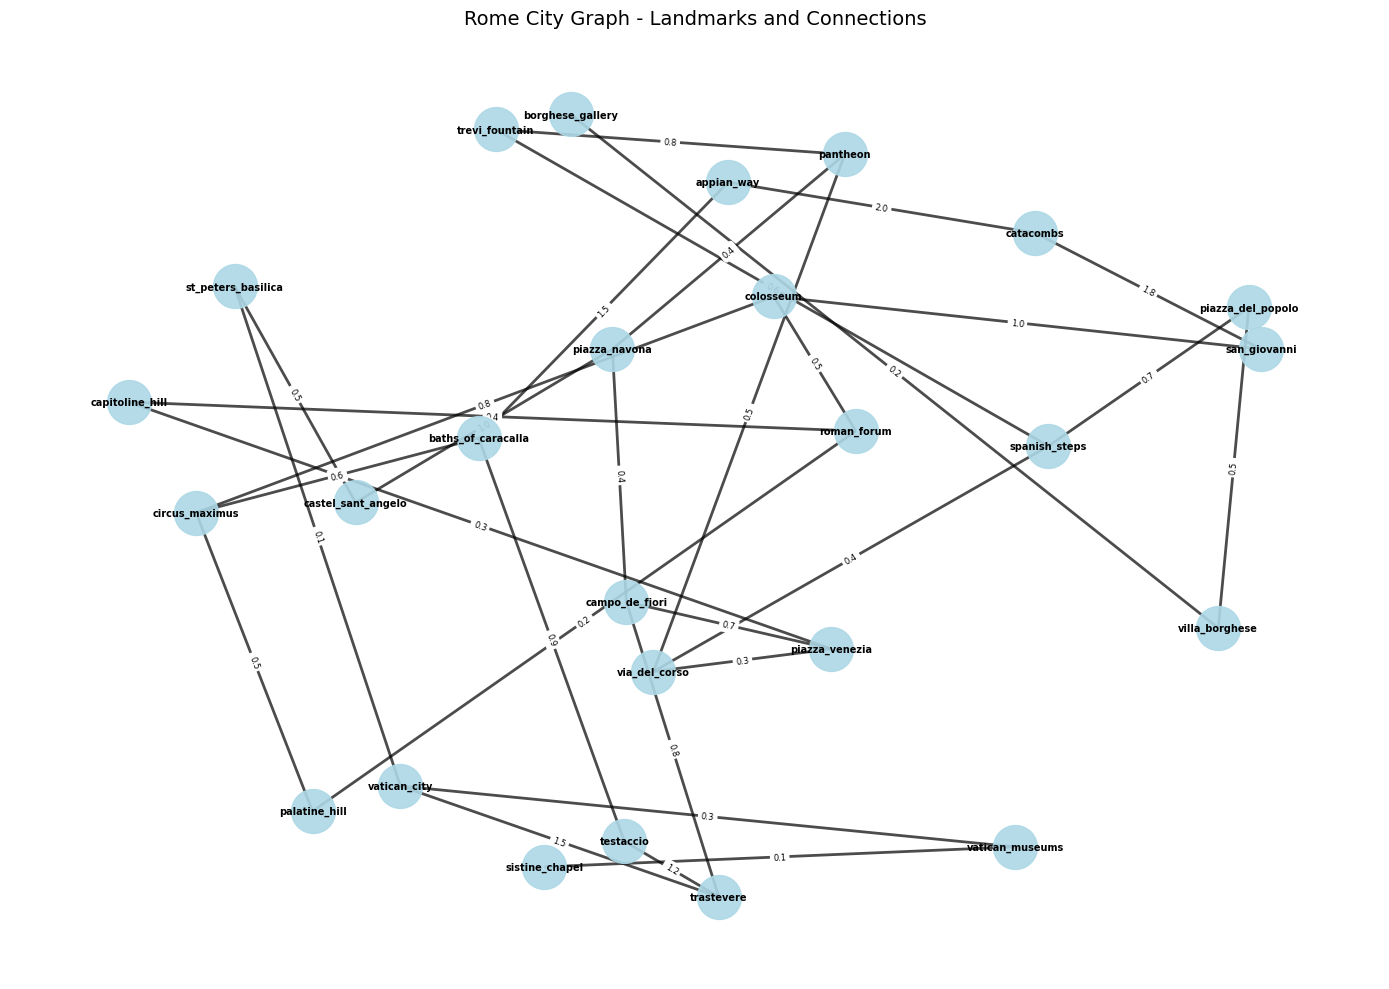

<Figure size 640x480 with 0 Axes>

In [25]:
# Create the Rome city graph
rome_graph = RomeCityGraph()

print("Rome City Graph Search Algorithms")
print(f"Graph created with {len(rome_graph.nodes)} landmarks")
print(f"Available landmarks: {', '.join(rome_graph.nodes)}")

# Visualize the graph
rome_graph.visualize_graph()
# save the plot 
plt.savefig("rome_city_graph.png")

In [16]:
class GraphSearchAlgorithms:
    def __init__(self, graph):
        self.graph = graph
        self.complexity_data = {}
    
    def measure_complexity(self, algorithm_name, func, *args, **kwargs):
        start_time = time.perf_counter()
        result = func(*args, **kwargs)
        end_time = time.perf_counter()
        execution_time = end_time - start_time
        
        path, visited_order, max_memory = result
        
        self.complexity_data[algorithm_name] = {
            'time': execution_time,
            'space': max_memory,
            'nodes_visited': len(visited_order),
            'path_length': len(path) if path else 0,
            'path': path,
            'visited_order': visited_order
        }
        
        return result

print("GraphSearchAlgorithms class initialized!")

GraphSearchAlgorithms class initialized!


In [17]:
def bfs(self, start, goal):
    """Breadth-First Search algorithm"""
    if start not in self.graph.nodes or goal not in self.graph.nodes:
        return [], [], 0
    
    queue = deque([(start, [start])])
    visited = set()
    visited_order = []
    max_memory = 0
    
    while queue:
        current_memory = sys.getsizeof(queue) + sys.getsizeof(visited)
        max_memory = max(max_memory, current_memory)
        
        current, path = queue.popleft()
        
        if current in visited:
            continue
            
        visited.add(current)
        visited_order.append(current)
        
        if current == goal:
            return path, visited_order, max_memory
        
        neighbors = self.graph.get_neighbors(current)
        for neighbor in neighbors:
            if neighbor not in visited:
                new_path = path + [neighbor]
                queue.append((neighbor, new_path))
    
    return [], visited_order, max_memory

# Add the method to the class
GraphSearchAlgorithms.bfs = bfs
print("BFS algorithm implemented!")

BFS algorithm implemented!


In [18]:
def dfs(self, start, goal):
    """Depth-First Search algorithm"""
    if start not in self.graph.nodes or goal not in self.graph.nodes:
        return [], [], 0
    
    stack = [(start, [start])]
    visited = set()
    visited_order = []
    max_memory = 0
    
    while stack:
        current_memory = sys.getsizeof(stack) + sys.getsizeof(visited)
        max_memory = max(max_memory, current_memory)
        
        current, path = stack.pop()
        
        if current in visited:
            continue
            
        visited.add(current)
        visited_order.append(current)
        
        if current == goal:
            return path, visited_order, max_memory
        
        neighbors = self.graph.get_neighbors(current)
        for neighbor in reversed(neighbors):
            if neighbor not in visited:
                new_path = path + [neighbor]
                stack.append((neighbor, new_path))
    
    return [], visited_order, max_memory

# Add the method to the class
GraphSearchAlgorithms.dfs = dfs
print("DFS algorithm implemented!")

DFS algorithm implemented!


In [19]:
def ucs(self, start, goal):
    """Uniform Cost Search algorithm"""
    if start not in self.graph.nodes or goal not in self.graph.nodes:
        return [], [], 0
    
    pq = [(0, start, [start])]
    visited = set()
    visited_order = []
    max_memory = 0
    
    while pq:
        current_memory = sys.getsizeof(pq) + sys.getsizeof(visited)
        max_memory = max(max_memory, current_memory)
        
        cost, current, path = heapq.heappop(pq)
        
        if current in visited:
            continue
            
        visited.add(current)
        visited_order.append(current)
        
        if current == goal:
            return path, visited_order, max_memory
        
        neighbors = self.graph.get_neighbors(current)
        for neighbor in neighbors:
            if neighbor not in visited:
                edge_cost = self.graph.get_weight(current, neighbor)
                new_cost = cost + edge_cost
                new_path = path + [neighbor]
                heapq.heappush(pq, (new_cost, neighbor, new_path))
    
    return [], visited_order, max_memory

# Add the method to the class
GraphSearchAlgorithms.ucs = ucs
print("UCS algorithm implemented!")

UCS algorithm implemented!


In [20]:
def print_results(self):
    """Print detailed results for all algorithms"""
    print("\nResults:")
    print("-" * 80)
    
    for alg_name, data in self.complexity_data.items():
        print(f"\n{alg_name.upper()}:")
        if data['path']:
            print(f"  Shortest path: {' -> '.join(data['path'])}")
            
            # Calculate total distance
            total_distance = 0
            for i in range(len(data['path']) - 1):
                total_distance += self.graph.get_weight(data['path'][i], data['path'][i+1])
            print(f"  Total distance: {total_distance:.1f} km")
        else:
            print("  No path found")
        
        print(f"  Visited order: {' -> '.join(data['visited_order'])}")
        print(f"  Nodes visited: {data['nodes_visited']}")
        print(f"  Time taken: {data['time']*1000:.4f} ms")
        print(f"  Space used: {data['space']} bytes")
    
    print("\nComplexity Analysis:")
    print("-" * 50)
    print("Algorithm | Time (ms) | Space (bytes) | Nodes visited | Path length")
    print("-" * 70)
    
    for alg_name, data in self.complexity_data.items():
        print(f"{alg_name.upper():<9} | {data['time']*1000:<9.4f} | {data['space']:<13} | "
              f"{data['nodes_visited']:<13} | {data['path_length']}")

def compare_algorithms(self, start, goal):
    """Compare all three algorithms"""
    print(f"Searching from {start} to {goal}")
    print("-" * 50)
    
    algorithms = [("bfs", self.bfs), ("dfs", self.dfs), ("ucs", self.ucs)]
    
    for name, algorithm in algorithms:
        self.measure_complexity(name, algorithm, start, goal)
    
    self.print_results()
    self.visualize_comparison()

# Add methods to the class
GraphSearchAlgorithms.print_results = print_results
GraphSearchAlgorithms.compare_algorithms = compare_algorithms
print("Results display methods implemented!")

Results display methods implemented!


In [21]:
def visualize_comparison(self):
    """Create visual comparison charts"""
    if not self.complexity_data:
        return
    
    algorithms = list(self.complexity_data.keys())
    times = [self.complexity_data[alg]['time'] * 1000 for alg in algorithms]
    spaces = [self.complexity_data[alg]['space'] for alg in algorithms]
    nodes_visited = [self.complexity_data[alg]['nodes_visited'] for alg in algorithms]
    path_lengths = [self.complexity_data[alg]['path_length'] for alg in algorithms]
    
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
    
    colors = ['#ff6b6b', '#4ecdc4', '#45b7d1']
    
    # Time comparison
    bars1 = ax1.bar(algorithms, times, color=colors)
    ax1.set_title('Execution Time')
    ax1.set_ylabel('Time (ms)')
    for i, bar in enumerate(bars1):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}', ha='center', va='bottom', fontsize=8)
    
    # Space comparison
    bars2 = ax2.bar(algorithms, spaces, color=colors)
    ax2.set_title('Memory Usage')
    ax2.set_ylabel('Memory (bytes)')
    for i, bar in enumerate(bars2):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}', ha='center', va='bottom', fontsize=8)
    
    # Nodes visited
    bars3 = ax3.bar(algorithms, nodes_visited, color=colors)
    ax3.set_title('Nodes Visited')
    ax3.set_ylabel('Number of nodes')
    for i, bar in enumerate(bars3):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}', ha='center', va='bottom', fontsize=8)
    
    # Path length
    bars4 = ax4.bar(algorithms, path_lengths, color=colors)
    ax4.set_title('Path Length')
    ax4.set_ylabel('Path length (nodes)')
    for i, bar in enumerate(bars4):
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height)}', ha='center', va='bottom', fontsize=8)
    
    plt.suptitle('Algorithm Performance Comparison', fontsize=14)
    plt.tight_layout()
    plt.show()

# Add method to the class
GraphSearchAlgorithms.visualize_comparison = visualize_comparison
print("Visualization method implemented!")

Visualization method implemented!


MAIN ANALYSIS
Searching from colosseum to vatican_city
--------------------------------------------------

Results:
--------------------------------------------------------------------------------

BFS:
  Shortest path: colosseum -> circus_maximus -> baths_of_caracalla -> testaccio -> trastevere -> vatican_city
  Total distance: 5.0 km
  Visited order: colosseum -> roman_forum -> circus_maximus -> san_giovanni -> palatine_hill -> capitoline_hill -> baths_of_caracalla -> catacombs -> piazza_venezia -> testaccio -> appian_way -> via_del_corso -> campo_de_fiori -> trastevere -> pantheon -> spanish_steps -> piazza_navona -> vatican_city
  Nodes visited: 18
  Time taken: 0.1634 ms
  Space used: 1488 bytes

DFS:
  Shortest path: colosseum -> roman_forum -> palatine_hill -> circus_maximus -> baths_of_caracalla -> testaccio -> trastevere -> campo_de_fiori -> piazza_navona -> castel_sant_angelo -> st_peters_basilica -> vatican_city
  Total distance: 6.7 km
  Visited order: colosseum -> roman_fo

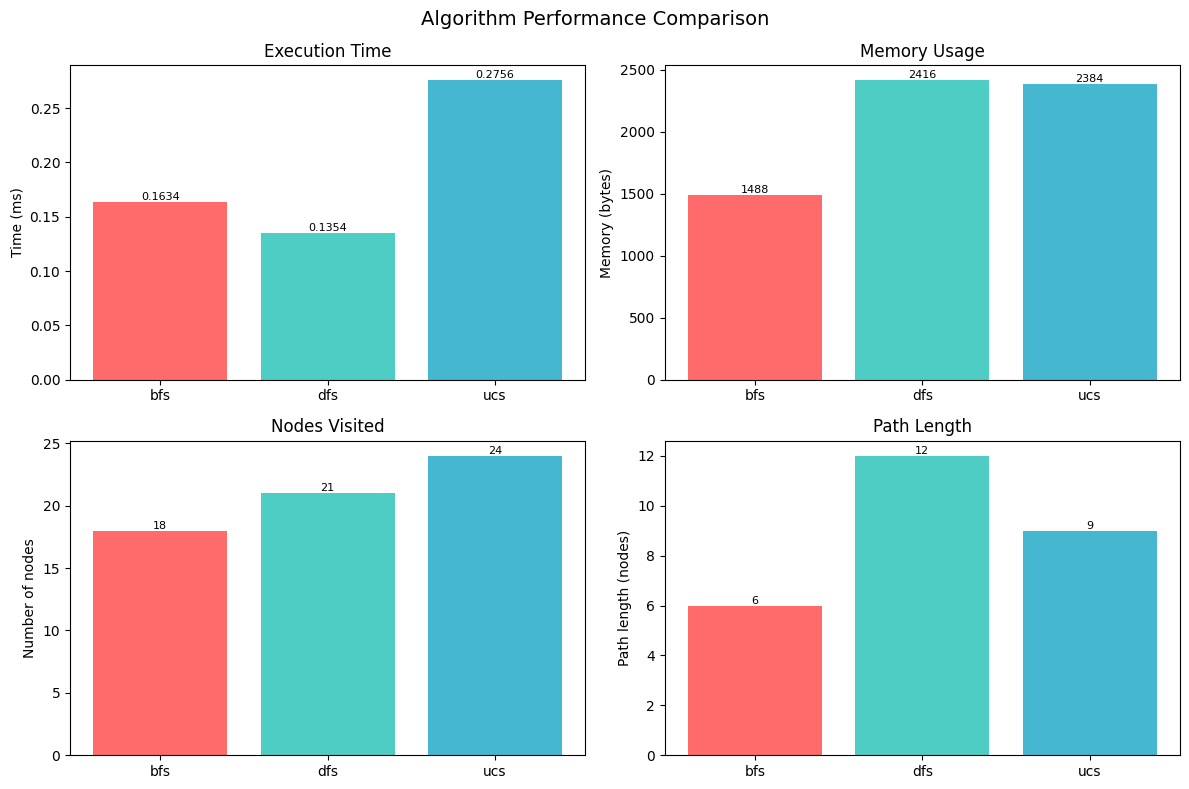

In [22]:
# Initialize the search algorithms
search_algorithms = GraphSearchAlgorithms(rome_graph)

# Main comparison: Colosseum to Vatican City
start_node = "colosseum"
goal_node = "vatican_city"

print("="*60)
print("MAIN ANALYSIS")
print("="*60)

search_algorithms.compare_algorithms(start_node, goal_node)


ADDITIONAL EXAMPLES

Example: trevi_fountain -> borghese_gallery
Searching from trevi_fountain to borghese_gallery
--------------------------------------------------

Results:
--------------------------------------------------------------------------------

BFS:
  Shortest path: trevi_fountain -> spanish_steps -> piazza_del_popolo -> villa_borghese -> borghese_gallery
  Total distance: 2.0 km
  Visited order: trevi_fountain -> pantheon -> spanish_steps -> via_del_corso -> piazza_navona -> piazza_del_popolo -> piazza_venezia -> campo_de_fiori -> castel_sant_angelo -> villa_borghese -> capitoline_hill -> trastevere -> st_peters_basilica -> borghese_gallery
  Nodes visited: 14
  Time taken: 0.1442 ms
  Space used: 1488 bytes

DFS:
  Shortest path: trevi_fountain -> pantheon -> via_del_corso -> spanish_steps -> piazza_del_popolo -> villa_borghese -> borghese_gallery
  Total distance: 3.1 km
  Visited order: trevi_fountain -> pantheon -> via_del_corso -> piazza_venezia -> capitoline_hill -

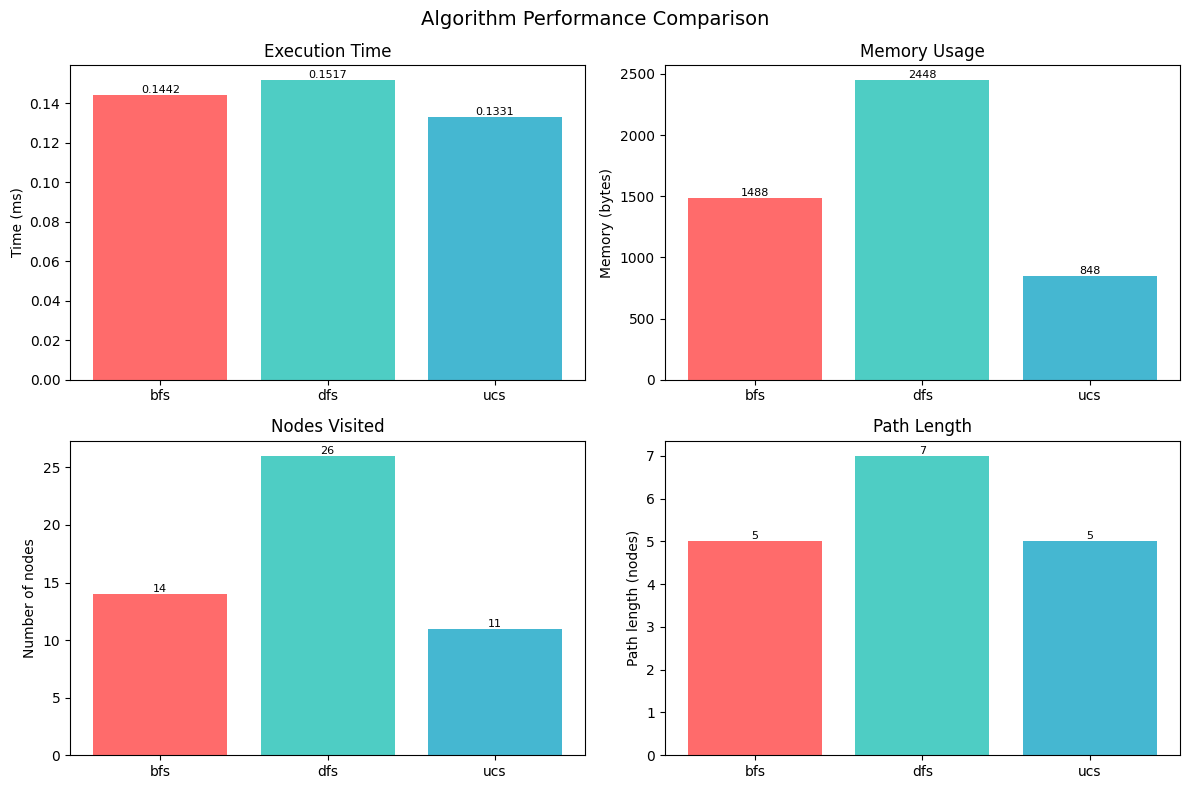


Example: pantheon -> appian_way
Searching from pantheon to appian_way
--------------------------------------------------

Results:
--------------------------------------------------------------------------------

BFS:
  Shortest path: pantheon -> piazza_navona -> campo_de_fiori -> trastevere -> testaccio -> baths_of_caracalla -> appian_way
  Total distance: 5.2 km
  Visited order: pantheon -> via_del_corso -> trevi_fountain -> piazza_navona -> piazza_venezia -> spanish_steps -> campo_de_fiori -> castel_sant_angelo -> capitoline_hill -> piazza_del_popolo -> trastevere -> st_peters_basilica -> roman_forum -> villa_borghese -> vatican_city -> testaccio -> colosseum -> palatine_hill -> borghese_gallery -> vatican_museums -> baths_of_caracalla -> circus_maximus -> san_giovanni -> sistine_chapel -> appian_way
  Nodes visited: 25
  Time taken: 0.1362 ms
  Space used: 3024 bytes

DFS:
  Shortest path: pantheon -> via_del_corso -> piazza_venezia -> capitoline_hill -> roman_forum -> colosseum -

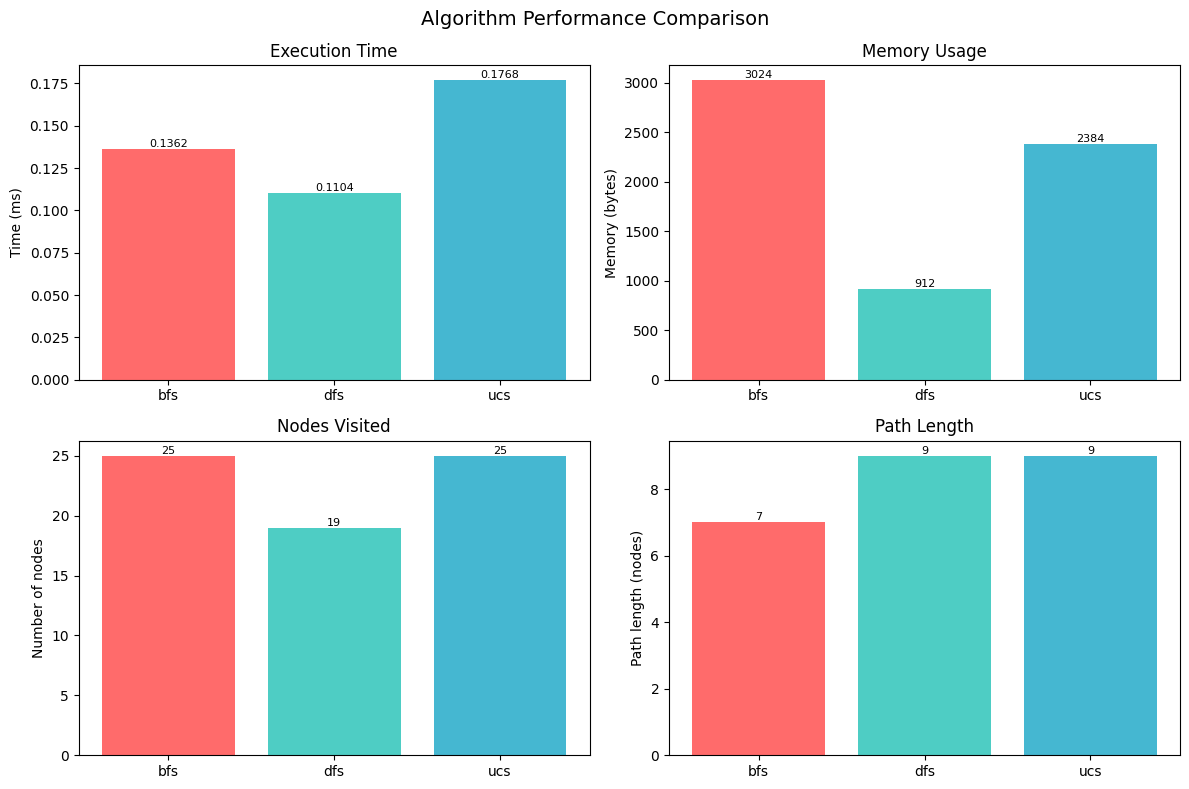

In [23]:
print("\n" + "="*60)
print("ADDITIONAL EXAMPLES")
print("="*60)

examples = [
    ("trevi_fountain", "borghese_gallery"),
    ("pantheon", "appian_way")
]

for start, goal in examples:
    print(f"\n{'='*40}")
    print(f"Example: {start} -> {goal}")
    print(f"{'='*40}")
    
    # Reset complexity data for new comparison
    search_algorithms.complexity_data = {}
    search_algorithms.compare_algorithms(start, goal)

In [12]:
def interactive_search():
    """Allow users to test different start and goal locations"""
    print("\nAvailable landmarks:")
    for i, landmark in enumerate(rome_graph.nodes, 1):
        print(f"{i:2d}. {landmark}")
    
    print("\nEnter landmark names to search between them.")
    print("Type 'quit' to exit.")
    
    while True:
        start = input("\nEnter start landmark: ").strip().lower()
        if start == 'quit':
            break
            
        goal = input("Enter goal landmark: ").strip().lower()
        if goal == 'quit':
            break
        
        if start in rome_graph.nodes and goal in rome_graph.nodes:
            search_algorithms.complexity_data = {}
            search_algorithms.compare_algorithms(start, goal)
        else:
            print("Invalid landmark names. Please check the spelling.")

# Uncomment the line below to run interactive search
# interactive_search()
print("Interactive search function ready! Uncomment the last line to use it.")

Interactive search function ready! Uncomment the last line to use it.
